# rctd-py Tutorial

**GPU-accelerated spatial transcriptomics deconvolution using RCTD (Robust Cell Type Decomposition).**

This notebook demonstrates an end-to-end RCTD workflow using the same **Slide-seq cerebellum** dataset from the [original spacexr vignette](https://raw.githack.com/dmcable/spacexr/master/vignettes/spatial-transcriptomics.html):
loading real single-cell reference and spatial data, building a `Reference` object, running RCTD
in all three modes (full, doublet, multi), and interpreting the results.

## Installation

```bash
uv pip install rctd-py   # or: pip install rctd-py
```

rctd-py uses a GPU when PyTorch sees one. GPU builds of PyTorch, older NVIDIA drivers and
offline installs are covered in the
[installation guide](https://rctd-py.readthedocs.io/en/latest/installation.html).

In [ ]:
import io
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata

from rctd import Reference, run_rctd, RCTDConfig

## 1. Download the spacexr Vignette Data

We use the exact same cerebellum data bundled with the R [spacexr](https://github.com/dmcable/spacexr) package:
- **Reference**: 475 single-cell RNA-seq profiles across 19 cerebellar cell types
- **Spatial**: 100 Slide-seq beads from mouse cerebellum

The data is small (~500 KB) and downloaded directly from the spacexr GitHub repository.
The first `run_rctd` call also downloads the likelihood tables (Q-matrices, 404 MB) once and
caches them.

In [ ]:
BASE = "https://raw.githubusercontent.com/dmcable/spacexr/master/inst/extdata"

def fetch_csv(url):
    """Download a CSV from URL and return as pandas DataFrame."""
    with urllib.request.urlopen(url) as resp:
        return pd.read_csv(io.BytesIO(resp.read()))

# Reference data
ref_dge = fetch_csv(f"{BASE}/Reference/Vignette/dge.csv")
ref_meta = fetch_csv(f"{BASE}/Reference/Vignette/meta_data.csv")
cell_type_dict = fetch_csv(f"{BASE}/Reference/Vignette/cell_type_dict.csv")

# Spatial data
spatial_dge = fetch_csv(f"{BASE}/SpatialRNA/Vignette/MappedDGEForR.csv")
bead_locs = fetch_csv(f"{BASE}/SpatialRNA/Vignette/BeadLocationsForR.csv")

print("Downloaded all files.")
print(f"Reference DGE: {ref_dge.shape}")
print(f"Spatial DGE: {spatial_dge.shape}")
print(f"Bead locations: {bead_locs.shape}")

Downloaded all files.
Reference DGE: (384, 476)
Spatial DGE: (378, 101)
Bead locations: (100, 3)


## 2. Prepare AnnData Objects

Convert the spacexr CSV format (genes × cells) into AnnData objects (cells × genes)
that `rctd-py` expects.

In [ ]:
# --- Build reference AnnData ---
# dge.csv: first column is gene names, remaining columns are cell barcodes
gene_names = ref_dge.iloc[:, 0].values
_counts = ref_dge.iloc[:, 1:].values.T.astype(np.float32)  # cells × genes
cell_barcodes = ref_dge.columns[1:].values
cluster_to_name = dict(zip(cell_type_dict['Cluster'], cell_type_dict['Name']))
# Map cluster numbers to cell type names
ref_meta_indexed = ref_meta.set_index('barcode')
cell_types = [cluster_to_name[ref_meta_indexed.loc[bc, 'cluster']] for bc in cell_barcodes]
ref_adata = anndata.AnnData(X=_counts, obs=pd.DataFrame({'cell_type': cell_types}, index=cell_barcodes))
ref_adata.var_names = pd.Index(gene_names)
print(f'Reference: {ref_adata.n_obs} cells × {ref_adata.n_vars} genes')
print(f'Cell types ({len(set(cell_types))}): {sorted(set(cell_types))}')

Reference: 475 cells × 384 genes
Cell types (19): ['Astrocytes', 'Bergmann', 'Candelabrum', 'Choroid', 'Endothelial', 'Ependymal', 'Fibroblast', 'Globular', 'Golgi', 'Granule', 'Lugaro', 'MLI1', 'MLI2', 'Macrophages', 'Microglia', 'Oligodendrocytes', 'Polydendrocytes', 'Purkinje', 'UBCs']


In [ ]:
# --- Build spatial AnnData ---
# MappedDGEForR.csv: first column is gene names, remaining are bead barcodes
sp_gene_names = spatial_dge.iloc[:, 0].values
sp_counts = spatial_dge.iloc[:, 1:].values.T.astype(np.float32)  # beads × genes
sp_barcodes = spatial_dge.columns[1:].values

# Bead coordinates
locs = bead_locs.set_index("barcodes")

spatial_adata = anndata.AnnData(
    X=sp_counts,
    obs=pd.DataFrame(
        {"x": locs.loc[sp_barcodes, "xcoord"].values,
         "y": locs.loc[sp_barcodes, "ycoord"].values},
        index=sp_barcodes,
    ),
)
spatial_adata.var_names = pd.Index(sp_gene_names)

print(f"Spatial: {spatial_adata.n_obs} beads × {spatial_adata.n_vars} genes")

Spatial: 100 beads × 378 genes


### The spatial data

Each bead at its position on the puck, coloured by its total UMI count. RCTD skips beads below
`UMI_min` (100 by default); the runs below set `UMI_min=1` to keep all 100 beads of this small
example.

Total UMI per bead: median 120, range 59-577; 71 of 100 beads have at least 100


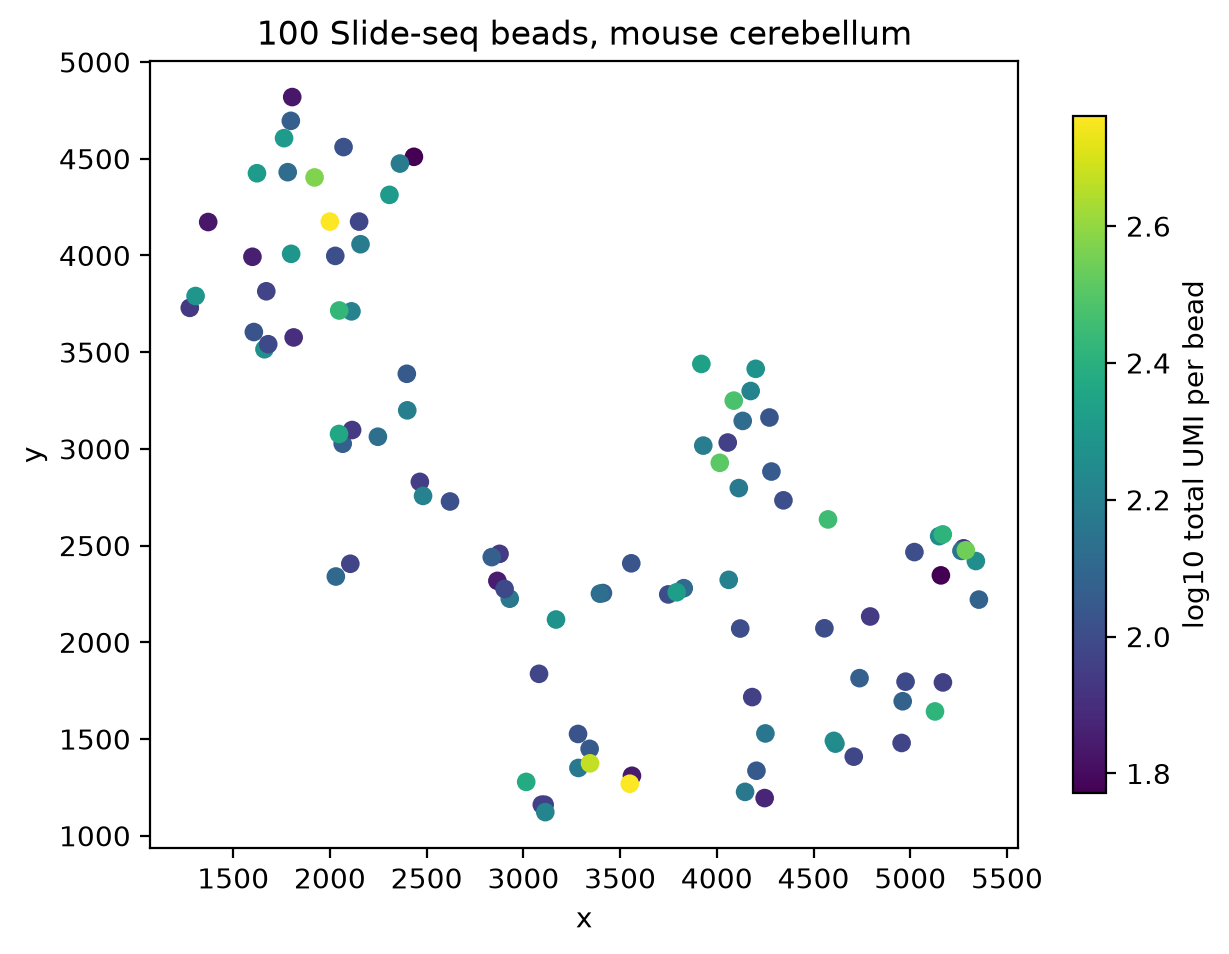

In [ ]:
_numi = np.asarray(spatial_adata.X.sum(axis=1)).ravel()
fig_beads, _ax = plt.subplots(figsize=(7, 5.5))
_sc = _ax.scatter(spatial_adata.obs["x"], spatial_adata.obs["y"], c=np.log10(_numi), cmap="viridis",
                  s=45, edgecolors="none")
_ax.set_aspect("equal")
_ax.set_xlabel("x")
_ax.set_ylabel("y")
_ax.set_title(f"{spatial_adata.n_obs} Slide-seq beads, mouse cerebellum")
fig_beads.colorbar(_sc, ax=_ax, shrink=0.8, label="log10 total UMI per bead")
print(f"Total UMI per bead: median {np.median(_numi):.0f}, range {_numi.min():.0f}-{_numi.max():.0f}; "
      f"{(_numi >= 100).sum()} of {len(_numi)} beads have at least 100")
fig_beads

## 3. Build Reference

The `Reference` class takes a single-cell `AnnData` object and computes per-type
expression profiles (mean UMI-normalized counts). Specify the `cell_type_col`
parameter to point to the column in `.obs` that holds cell type labels.

In [ ]:
reference = Reference(ref_adata, cell_type_col="cell_type")
print(f"Reference profiles: {reference.profiles.shape}")
print(f"Cell types: {reference.cell_type_names}")

Reference profiles: (384, 19)
Cell types: ['Astrocytes', 'Bergmann', 'Candelabrum', 'Choroid', 'Endothelial', 'Ependymal', 'Fibroblast', 'Globular', 'Golgi', 'Granule', 'Lugaro', 'MLI1', 'MLI2', 'Macrophages', 'Microglia', 'Oligodendrocytes', 'Polydendrocytes', 'Purkinje', 'UBCs']


## 4. Run RCTD

RCTD supports three deconvolution modes:

| Mode | Description | Best for |
|------|-------------|----------|
| `full` | Estimates continuous weights for all cell types simultaneously | Visium, continuous mixtures |
| `doublet` | Classifies each bead as singlet or doublet, assigns 1–2 types | Slide-seq, Visium HD bins, segmented cells (Xenium, MERFISH, CosMx) |
| `multi` | Greedy forward selection of up to 4 cell types per bead | Spots expected to hold more than 2 types (an alternative to `full`) |

### Doublet Mode (the default)

This is the mode used in the original spacexr vignette. It classifies each bead as
a singlet (one dominant cell type) or doublet (two cell types).

In [ ]:
from rctd import SPOT_CLASS_NAMES

class_labels = dict(enumerate(SPOT_CLASS_NAMES))

In [ ]:
# Use UMI_min=1 for this small tutorial dataset to keep all beads
_config = RCTDConfig(UMI_min=1, UMI_min_sigma=1)
_t0 = time.time()
result_doublet = run_rctd(spatial_adata, reference, mode='doublet', config=_config)
t_doublet = time.time() - _t0
print(f'Doublet mode: {t_doublet:.1f}s')
classes, _counts = np.unique(result_doublet.spot_class, return_counts=True)
for cl, ct in zip(classes, _counts):
    print(f'  {class_labels.get(cl, cl)}: {ct}')

Gene lists: bulk=356, reg=341 (from 378 common)
Fitting bulk platform effects...
Using 341 DE genes for pixel-level fitting
Estimating sigma...
Chosen sigma: 0.84 (24.4s)
Auto batch size: 200000
Running in doublet mode...
  [doublet] Step 1/6: full-mode fit (100 pixels, K=19)...
  [doublet] Step 1 done (0.9s)
  [doublet] Step 3: pairwise scoring (1051 triples)...
  [doublet] Step 3 done (0.2s)
  [doublet] Step 4: singlet scoring (484 singles)...
  [doublet] Step 4 done (0.7s)
  [doublet] Step 5: classification (100 pixels)...
  [doublet] Step 5 done (0.0s)
  [doublet] Step 6: final decomposition (100 pixels)...
  [doublet] Step 6 done (0.0s)
  [doublet] Total doublet mode: 1.9s
Doublet mode: 30.5s
  reject: 16
  singlet: 64
  doublet_certain: 10
  doublet_uncertain: 10


### Full Mode

Estimates a continuous weight vector over all cell types for every bead.
Most flexible — recommended when beads may contain mixtures of more than two types.

In [ ]:
_config = RCTDConfig(UMI_min=1, UMI_min_sigma=1)
_t0 = time.time()
result_full = run_rctd(spatial_adata, reference, mode='full', config=_config)
t_full = time.time() - _t0
print(f'Full mode: {t_full:.1f}s')
print(f'Weights shape: {result_full.weights.shape}')
print(f'Converged: {result_full.converged.sum()}/{len(result_full.converged)} beads')

Gene lists: bulk=356, reg=341 (from 378 common)
Fitting bulk platform effects...
Using 341 DE genes for pixel-level fitting
Estimating sigma...
Chosen sigma: 0.84 (0.4s)
Auto batch size: 200000
Running in full mode...
Full mode: 4.0s
Weights shape: (100, 19)
Converged: 100/100 beads


### Multi Mode

Greedy forward selection, adding cell types one at a time until adding another
no longer improves the fit. Max types per bead controlled by `RCTDConfig.MAX_MULTI_TYPES`.

In [ ]:
_config = RCTDConfig(UMI_min=1, UMI_min_sigma=1)
_t0 = time.time()
result_multi = run_rctd(spatial_adata, reference, mode='multi', config=_config)
t_multi = time.time() - _t0
print(f'Multi mode: {t_multi:.1f}s')
print(f'Types per bead: min={result_multi.n_types.min()}, max={result_multi.n_types.max()}')

Gene lists: bulk=356, reg=341 (from 378 common)
Fitting bulk platform effects...
Using 341 DE genes for pixel-level fitting
Estimating sigma...
Chosen sigma: 0.84 (0.5s)
Auto batch size: 200000
Running in multi mode...
Multi mode: 6.4s
Types per bead: min=1, max=2


The first `run_rctd` call in a session also compiles the solver kernels with
`torch.compile`. That one-off cost dominates the runtime on a dataset this small, so the
timings printed above say little about speed; see the
[benchmarks](https://rctd-py.readthedocs.io/en/latest/benchmarks.html) for runtimes on real data.

## 5. Interpreting Results

The `result_full.weights` matrix has shape `(n_beads, n_types)`. Following
R spacexr's `fitPixels(..., constrain=FALSE)` convention, full-mode weights
are the output of a non-negativity-constrained least-squares fit and are
**not** projected onto the simplex — rows typically sum to <1 (sparse beads
are common in Slide-seq) and individual entries can be slightly negative
due to numerical slack.

For downstream analyses that assume proportions (correlation, Euclidean /
cosine distance, JSD, plotting as a stacked bar):

```python
W = np.maximum(result_full.weights, 0)               # clip slack
W_prop = W / np.maximum(W.sum(axis=1, keepdims=True), 1e-10)
```

Doublet mode (`result_doublet.weights_doublet`) and multi mode
(`result_multi.sub_weights[n, :n_types[n]]`) are already normalized to
sum to 1.

In [ ]:
# Dominant cell type per bead (full mode)
cell_type_names = reference.cell_type_names
dominant_idx = np.argmax(result_full.weights, axis=1)
dominant_names = [cell_type_names[_i] for _i in dominant_idx]
print('Weight statistics per cell type (full mode):')
# Weight statistics
for _i, name in enumerate(cell_type_names):
    w = result_full.weights[:, _i]
    if w.max() > 0.01:
        print(f'  {name:20s}: mean={w.mean():.3f}, max={w.max():.3f}')

Weight statistics per cell type (full mode):
  Astrocytes          : mean=0.036, max=0.382
  Bergmann            : mean=0.029, max=0.462
  Candelabrum         : mean=0.009, max=0.355
  Choroid             : mean=0.004, max=0.075
  Endothelial         : mean=0.021, max=0.150
  Ependymal           : mean=0.043, max=0.225
  Fibroblast          : mean=0.060, max=0.428
  Globular            : mean=0.004, max=0.299
  Golgi               : mean=0.016, max=0.495
  Granule             : mean=0.258, max=0.679
  Lugaro              : mean=0.006, max=0.119
  MLI1                : mean=0.013, max=0.542
  MLI2                : mean=0.015, max=0.536
  Macrophages         : mean=0.015, max=0.134
  Microglia           : mean=0.010, max=0.147
  Oligodendrocytes    : mean=0.028, max=0.484
  Polydendrocytes     : mean=0.005, max=0.119
  Purkinje            : mean=0.096, max=0.814
  UBCs                : mean=0.011, max=0.193


## 6. Visualization

### Spatial Maps

Each panel shows the Slide-seq beads colored by the RCTD result for that mode.

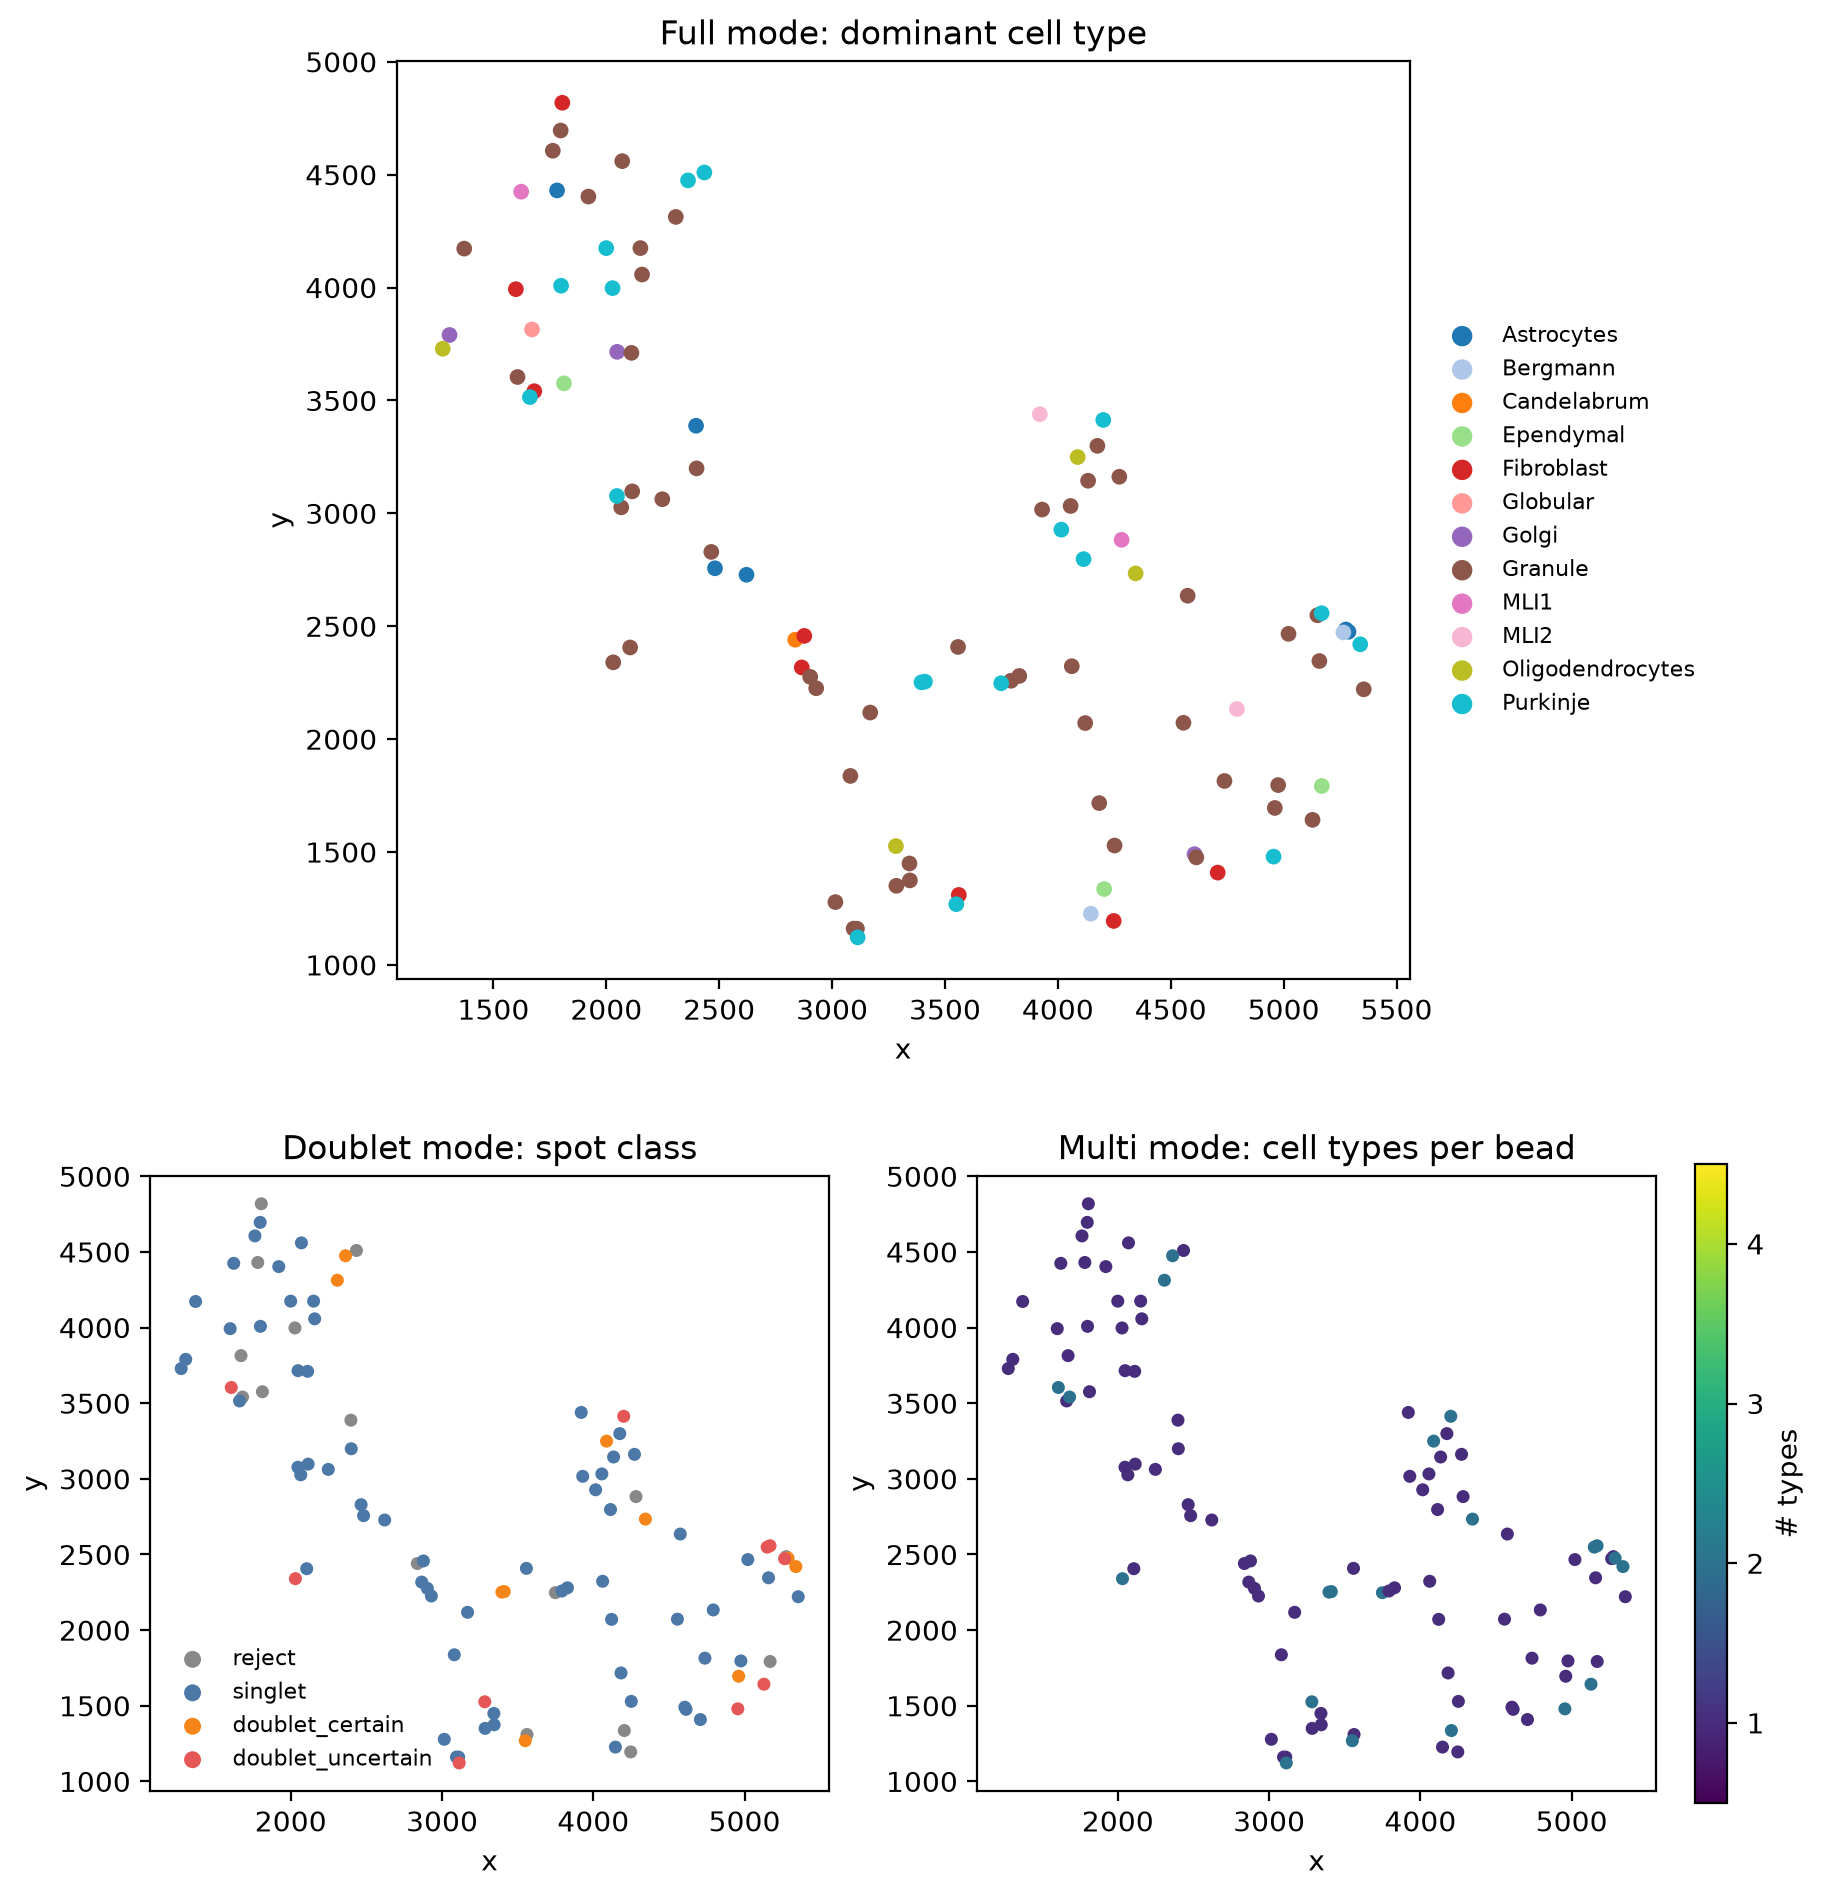

In [ ]:
_x = spatial_adata.obs["x"].values
_y = spatial_adata.obs["y"].values
fig_spatial = plt.figure(figsize=(9, 9.5), layout="constrained")
_gs = fig_spatial.add_gridspec(2, 2, height_ratios=[1.15, 1])
_full, _dbl, _multi = (fig_spatial.add_subplot(_gs[0, :]), fig_spatial.add_subplot(_gs[1, 0]),
                       fig_spatial.add_subplot(_gs[1, 1]))

# Full mode: dominant cell type, one legend entry per type that is dominant somewhere
_cmap = plt.colormaps.get_cmap("tab20").resampled(len(cell_type_names))
for _k in np.unique(dominant_idx):
    _m = dominant_idx == _k
    _full.scatter(_x[_m], _y[_m], color=_cmap(_k), s=32, edgecolors="none", label=cell_type_names[_k])
_full.set_title("Full mode: dominant cell type")
_full.legend(fontsize=8, markerscale=1.3, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)

# Doublet mode: spot class
_class_colors = {0: "#888888", 1: "#4C78A8", 2: "#F58518", 3: "#E45756"}
for _cls, _color in _class_colors.items():
    _m = result_doublet.spot_class == _cls
    if _m.any():
        _dbl.scatter(_x[_m], _y[_m], color=_color, s=22, edgecolors="none", label=class_labels[_cls])
_dbl.set_title("Doublet mode: spot class")
_dbl.legend(fontsize=8, markerscale=1.3, loc="lower left", frameon=False)

# Multi mode: number of cell types kept per bead
_sc = _multi.scatter(_x, _y, c=result_multi.n_types, cmap="viridis", vmin=0.5, vmax=4.5, s=22,
                     edgecolors="none")
_multi.set_title("Multi mode: cell types per bead")
fig_spatial.colorbar(_sc, ax=_multi, ticks=[1, 2, 3, 4], shrink=0.8, label="# types")

for _ax in (_full, _dbl, _multi):
    _ax.set_aspect("equal")
    _ax.set_xlabel("x")
    _ax.set_ylabel("y")
fig_spatial

### Weight Heatmap

Full-mode weights across all beads, for the cell types with a mean weight above 0.01. The
weights are not normalised (see above), so a bead's row need not sum to 1.

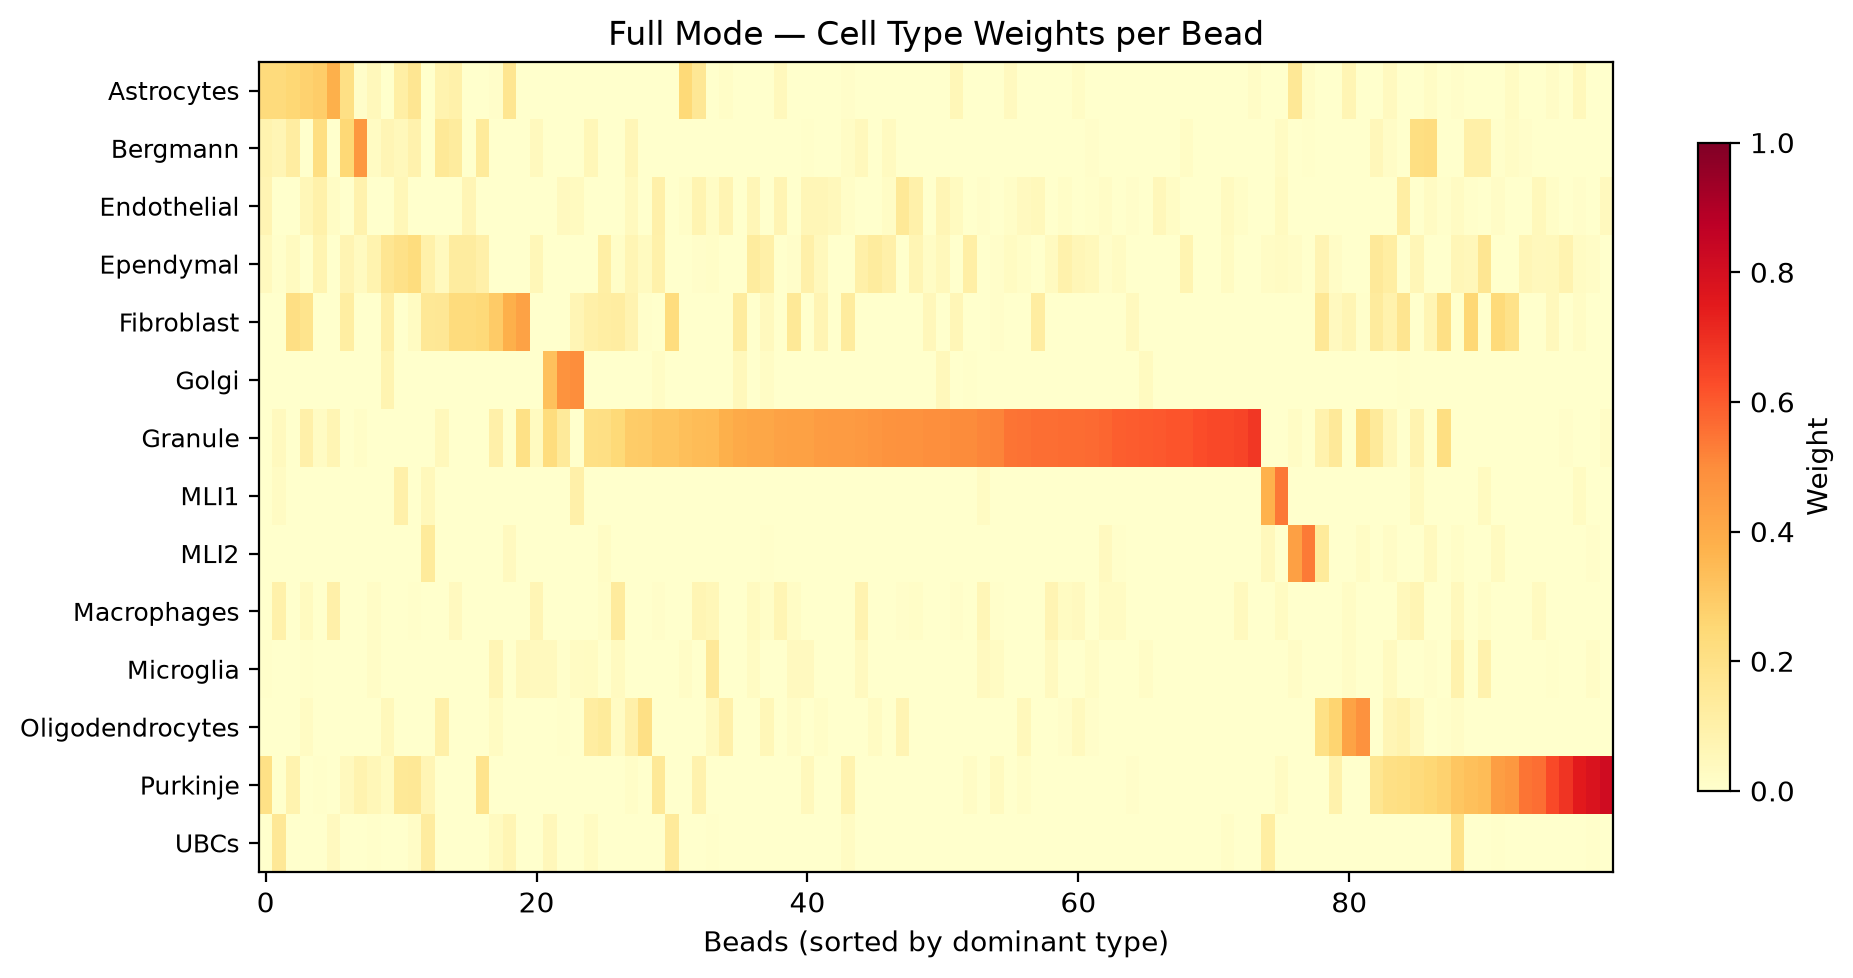

In [ ]:
# Weight heatmap (full mode, top cell types)
# Sort beads by dominant type for cleaner visualization
order = np.lexsort((result_full.weights.max(axis=1), dominant_idx))
active_mask = result_full.weights.mean(axis=0) > 0.01
# Show only cell types with mean weight > 1%
active_names = [cell_type_names[_i] for _i in range(len(cell_type_names)) if active_mask[_i]]
active_weights = result_full.weights[order][:, active_mask]
fig_heatmap, ax_heatmap = plt.subplots(figsize=(10, 5))
im = ax_heatmap.imshow(active_weights.T, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
ax_heatmap.set_yticks(range(len(active_names)))
ax_heatmap.set_yticklabels(active_names, fontsize=9)
ax_heatmap.set_xlabel('Beads (sorted by dominant type)')
ax_heatmap.set_title('Full Mode — Cell Type Weights per Bead')
plt.colorbar(im, ax=ax_heatmap, label='Weight', shrink=0.8)
plt.tight_layout()
fig_heatmap

### Doublet Mode Details

Doublet mode reports two cell types and their weights for every bead, whatever its class.
Both types apply only to doublets; for a singlet the first type is the call, and rejects
should be discarded.

In [ ]:
first_names = [cell_type_names[_i] for _i in result_doublet.first_type]
second_names = [cell_type_names[_i] for _i in result_doublet.second_type]
print('Doublet mode — first 10 beads:')
print(f"{'Bead':<20s} {'Class':<22s} {'Type 1':<18s} {'Type 2':<18s} {'Weight 1':>8s} {'Weight 2':>8s}")
print('-' * 96)
for _i in range(min(10, len(first_names))):
    _cls = class_labels.get(int(result_doublet.spot_class[_i]), '?')
    w1 = result_doublet.weights_doublet[_i, 0]
    w2 = result_doublet.weights_doublet[_i, 1]
    print(f'{spatial_adata.obs_names[_i]:<20s} {_cls:<22s} {first_names[_i]:<18s} {second_names[_i]:<18s} {w1:>8.3f} {w2:>8.3f}')

Doublet mode — first 10 beads:
Bead                 Class                  Type 1             Type 2             Weight 1 Weight 2
------------------------------------------------------------------------------------------------
TTGGACGTTTCAAT       doublet_certain        Purkinje           Ependymal             0.593    0.407
CACGGCCATATTGC       singlet                Granule            Endothelial           0.927    0.073
CGCCCCCCACCCCT       singlet                Fibroblast         Candelabrum           0.689    0.311
CCCCCCCCATTGAA       doublet_uncertain      Granule            Oligodendrocytes      0.650    0.350
CGCTTGGCATTTAC       singlet                Granule            Candelabrum           0.797    0.203
CGTGAGTTTCTCCT       singlet                Purkinje           Ependymal             0.943    0.057
ATTCAGTCGCATTA       singlet                Purkinje           Endothelial           0.943    0.057
CCAACTCCCCTACT       singlet                Bergmann           Purkinje 

## 7. Configuration

`RCTDConfig` controls all algorithm hyperparameters. The most commonly
tuned ones:

| Parameter | Default | Description |
|-----------|---------|-------------|
| `UMI_min` | 100 | Minimum UMI count to include a bead |
| `UMI_min_sigma` | 300 | Minimum UMI count for beads used in sigma estimation |
| `N_fit` | 100 | Number of beads used to estimate sigma |
| `MAX_MULTI_TYPES` | 4 | Max cell types per bead in multi mode |
| `DOUBLET_THRESHOLD` | 20.0 | Singlet-vs-doublet log-likelihood gap (doublet mode) |
| `CONFIDENCE_THRESHOLD` | 5.0 | Confidence margin for selected types (doublet/multi) |
| `compile` | `True` | Use `torch.compile`; set `False` (or pass `--no-compile`) to fall back to TorchScript JIT (no CUDA dev headers needed) |

See the [`RCTDConfig` reference](https://rctd-py.readthedocs.io/en/latest/generated/rctd.RCTDConfig.html)
for the full list including bulk-fit cutoffs (`gene_cutoff`, `fc_cutoff`, …).

The `batch_size` argument to `run_rctd` controls how many beads are processed
per GPU kernel launch. Larger values use more VRAM but may be faster.

In [ ]:
# Custom configuration example
_config = RCTDConfig(UMI_min=100, N_fit=100, MAX_MULTI_TYPES=4)
result = run_rctd(spatial_adata, reference, mode='full', config=_config, batch_size=5000)
print(f'Custom run: {result.weights.shape}')

UMI filter: kept 71/100 pixels (UMI range [100, 20000000])
Gene lists: bulk=353, reg=338 (from 378 common)
Fitting bulk platform effects...
Using 338 DE genes for pixel-level fitting
Estimating sigma...
Chosen sigma: 0.82 (0.4s)
Running in full mode...
Custom run: (71, 19)
